In [1]:
import argparse
import os
import sys
import torchvision
import torch
from torch.serialization import default_restore_location
from torch.distributions import Poisson
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as patches

sys.path.append('../')
import data
import models
import utils

In [2]:
checkpoint_path = '../checkpoints/unet-128-small.pt'

In [3]:
USE_CUDA = True
device = torch.device("cuda") if (
        torch.cuda.is_available() and USE_CUDA) else torch.device("cpu")

In [4]:
def load_model(checkpoint_path):
    state_dict = torch.load( checkpoint_path, map_location=lambda s,
                                l: default_restore_location(s,"cpu"),
                             weights_only=False,
                    )
    
    args = argparse.Namespace(
        **{**vars(state_dict["args"])})
    model = models.build_model(args).to(device)
    model.load_state_dict(state_dict["model"][0])
    model.eval()
    return model

In [5]:
net = load_model(checkpoint_path).to(device)
_ = net.eval()

In [6]:
full_x = torch.from_numpy(
    np.load('../images/real_data/00000.npy')
).float()

original_ix = 275
original_iy = 962

half = 200

x0 = original_ix - half  # 75
y0 = original_iy - half  # 762

x = full_x[:, y0:y0 + 400, x0:x0 + 400].contiguous()

noisy = x.unsqueeze(0).to(device)
noisy.requires_grad_(True)

denoised = net(noisy)

print(noisy.shape)

torch.Size([1, 1, 400, 400])


In [7]:
noisy = x.to(device).unsqueeze(0).requires_grad_(True)
with torch.no_grad():
    denoised = net(noisy)

In [8]:
def visualize_denoising(list_of_images, 
                        labels = ['clean', 'noisy', 'denoised'], 
                        figsize = (15, 5), 
                        vmax = 1.0, vmin = 0.0, psnr = True):
    fig, axes = plt.subplots(nrows=1, ncols=3, sharex = True, sharey = True, figsize = figsize)
    
    clean = list_of_images[0]
    for ax, image, label in zip(axes, list_of_images, labels):
        ax.imshow(image.data.cpu().numpy()[0, 0], cmap='gray', vmax=vmax, vmin = vmin)
        if psnr:
            psnr = utils.psnr(clean, image)
            ax.set_title(f"{label} {round(psnr, 2)}")

/home/sungho/Documents/GitHub/electron-microscopy-denoising/.venv/lib/python3.14/site-packages/skimage/metrics/simple_metrics.py:171: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


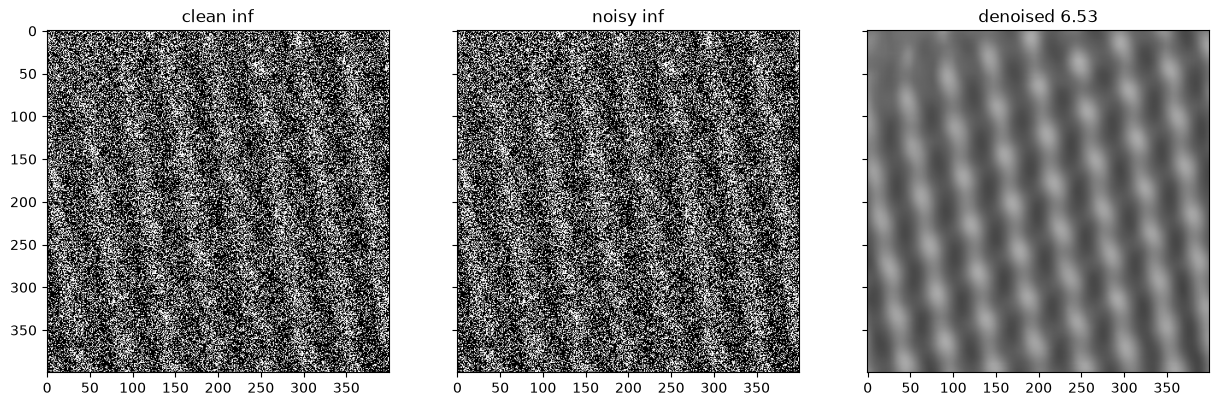

In [9]:
visualize_denoising([noisy, noisy, denoised], vmax = 1.0, vmin = 0)

In [10]:
pixels = [(200, 200)]

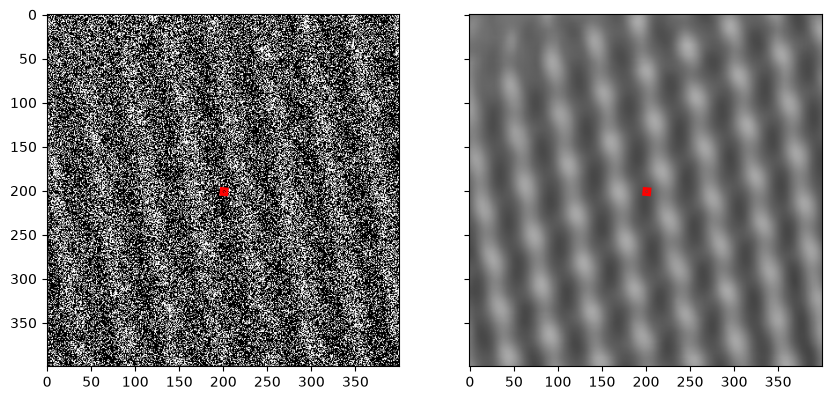

1 0.3129804 0.032621995 0.28035843


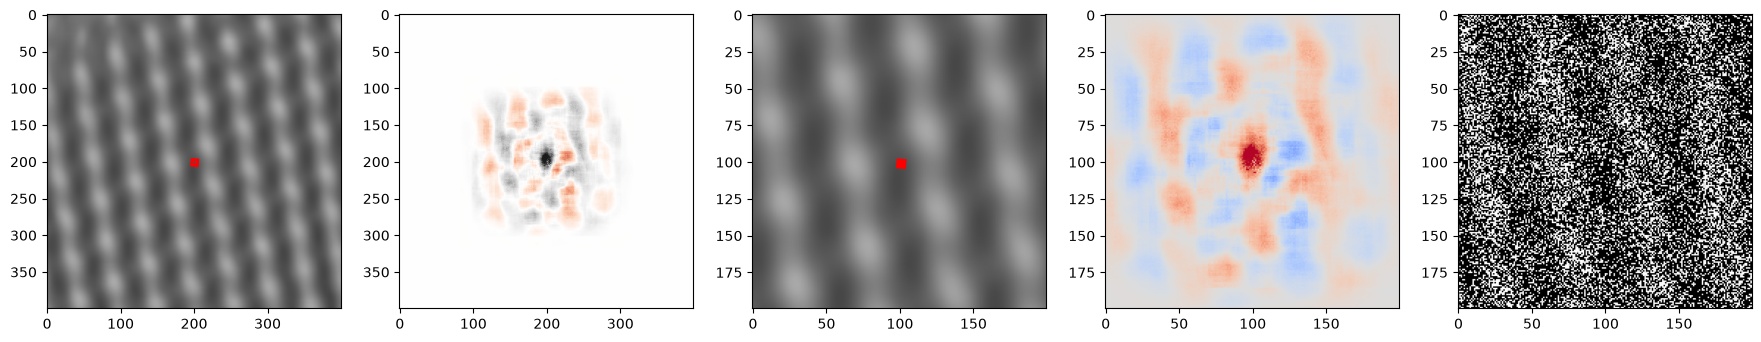

In [11]:
fig, axes = plt.subplots(nrows=1, ncols=2, sharex = True, sharey = True, figsize = (10, 5))

# plot noisy
axes[0].imshow(noisy[0, 0].cpu().data.numpy(), 'gray', vmin = 0, vmax = 1)
  
# denoise
noisy.requires_grad = True
denoised = net(noisy)

# plot denoised
axes[1].imshow(denoised[0, 0].cpu().data.numpy(), 'gray', vmin = 0, vmax = 1)

for j, (ix, iy) in enumerate(pixels):
    pa1 = patches.Rectangle((ix,iy), width=2, height=2, angle=5, edgecolor = [1,0,0], facecolor='red', lw=5)
    pa2 = patches.Rectangle((ix,iy), width=2, height=2, angle=5, edgecolor = [1,0,0], facecolor='red', lw=5)
    axes[0].add_patch(pa1)
    axes[1].add_patch(pa2)

plt.show()


width = 100
photo_num = 0
for j, (ix, iy) in enumerate(pixels):
    
    fig, axes = plt.subplots(nrows=1, ncols=5, figsize = (22, 6))
    
    im = axes[0].imshow(denoised[0, 0].cpu().data.numpy(), 'gray', vmin = 0, vmax = 1)
    
    
    filt = torch.autograd.grad(denoised[0,0,iy,ix], noisy, retain_graph=True)[0][0,0].cpu().data.numpy() 
    
    photo_num += 1
    print(photo_num, denoised[0, 0, iy, ix].cpu().data.numpy(), 
          np.sum(noisy.cpu().data.numpy()*filt), 
          denoised[0, 0, iy, ix].cpu().data.numpy() - np.sum(noisy.cpu().data.numpy()*filt) )
    
    limit =  max(np.abs(np.min( filt)), np.abs(np.max( filt)))
    limit /= 2
    im = axes[1].imshow(filt, 'RdGy', vmin= -limit, vmax = limit)
    axes[2].imshow(denoised[0, 0, iy-width:iy+width, ix-width:ix+width].cpu().data.numpy(), 'gray', vmin = 0, vmax = 1)
    axes[3].imshow(filt[iy-width:iy+width, ix-width:ix+width], 'coolwarm' if True else 'gray', vmin= -limit, vmax = limit)
    axes[4].imshow(noisy[0, 0, iy-width:iy+width, ix-width:ix+width].cpu().data.numpy(), 'gray', vmin = 0, vmax = 1)
    
    pa1 = patches.Rectangle((ix,iy), width=2, height=2, angle=5, edgecolor = [1,0,0], facecolor='red', lw=5)
    axes[0].add_patch(pa1)
    
    pa2 = patches.Rectangle( ( width, width) , 
                    width=2, height=2, angle=5, edgecolor = [1,0,0], facecolor='red', lw=5)
    axes[2].add_patch(pa2)
    
    plt.show()

# Paper Plot

In [12]:
# ix, iy = pixels[8]
ix = 200
iy = 200
# ix = 535
# iy = 820
# ix = 450
# iy = 600
# ix = 300
# iy = 350

In [13]:
# The input is now a 400x400 crop centered on the original (275, 962) pixel.
# Use coordinates local to that crop.
ix_list = [200]
iy_list = [200]

In [14]:
width = 100

In [15]:
linewidth = 3

In [16]:
xc = 0
yc = 0
idx = 1

In [17]:
figsize = (20, 20)

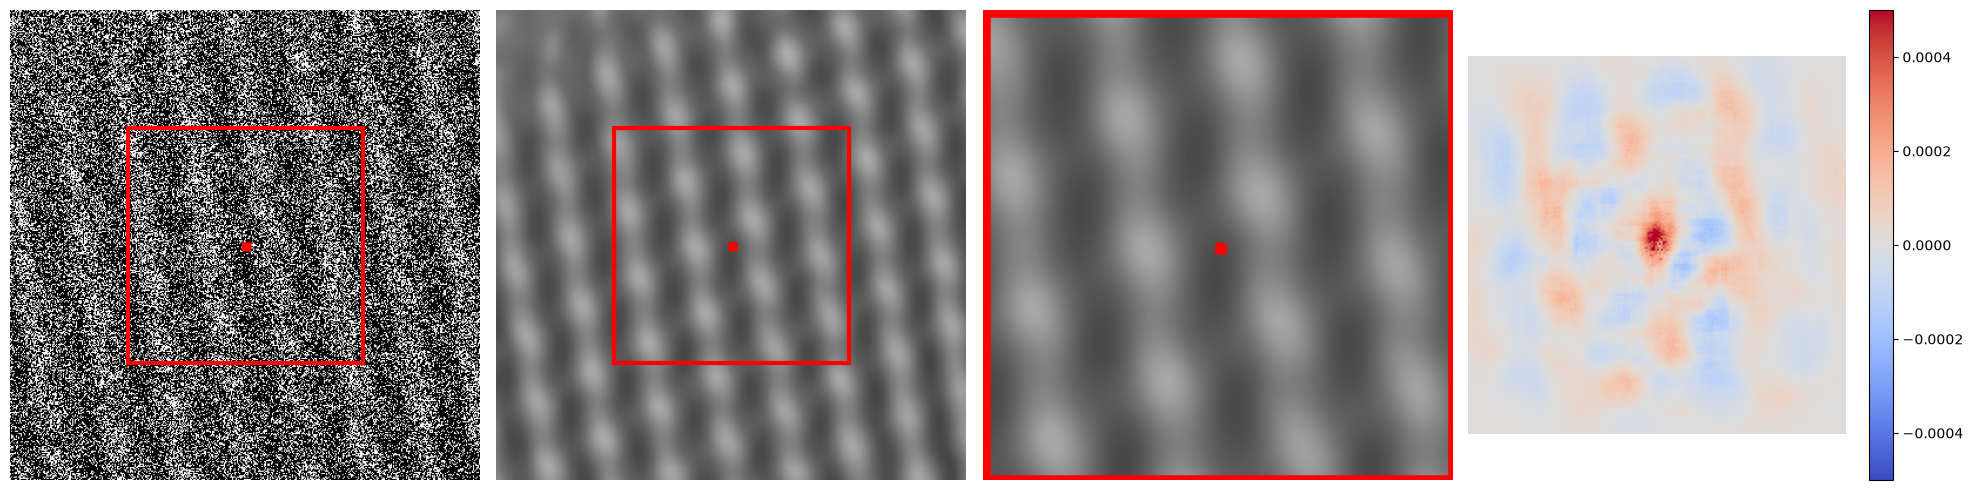

In [18]:
# Rebuild the graph in case an earlier autograd.grad call released it.
noisy = x.unsqueeze(0).to(device).requires_grad_(True)
denoised = net(noisy)

n_points = len(ix_list)
fig, axes = plt.subplots(nrows=n_points, ncols=4, squeeze=False, sharex=False, sharey=False, figsize=(20, 5 * n_points))

for i in range(n_points):
    ix = ix_list[i]    
    iy = iy_list[i]
    
    axes[i][0].imshow(noisy[0,0, xc:xc+1200, yc:yc+1200].data.cpu().numpy(), cmap='gray', vmax=1.0, vmin = 0.0)
    pa1 = patches.Rectangle((ix,iy), width=2, height=2, angle=5, edgecolor = [1,0,0], facecolor='red', lw=5)
    axes[i][0].add_patch(pa1)
    rect1 = patches.Rectangle((ix-width,iy-width), width*2, width*2, linewidth= linewidth, edgecolor='r',facecolor='none')
    axes[i][0].add_patch(rect1)
    axes[i][0].axis('off')
    
    axes[i][1].imshow(denoised[0,0, :1200, :1200].data.cpu().numpy(), cmap='gray', vmax=1.0, vmin = 0.0)
    pa1 = patches.Rectangle((ix,iy), width=2, height=2, angle=5, edgecolor = [1,0,0], facecolor='red', lw=5)
    axes[i][1].add_patch(pa1)
    rect1 = patches.Rectangle((ix-width,iy-width), width*2, width*2, linewidth= linewidth, edgecolor='r',facecolor='none')
    axes[i][1].add_patch(rect1)
    axes[i][1].axis('off')
    
    axes[i][2].imshow(denoised[0,0, iy-width:iy+width, ix-width:ix+width].data.cpu().numpy(), cmap='gray', vmax=1.0, vmin = 0.0)
    pa1 = patches.Rectangle((width,width), width=2, height=2, angle=5, edgecolor = [1,0,0], facecolor='red', lw=5)
    axes[i][2].add_patch(pa1)
    rect1 = patches.Rectangle((0,0), width*2, width*2, linewidth= linewidth*3, edgecolor='r',facecolor='none')
    axes[i][2].add_patch(rect1)
    axes[i][2].axis('off')
    
    filt = torch.autograd.grad(denoised[0,0,iy,ix], noisy, retain_graph=(i < n_points - 1))[0][0,0].detach().cpu().numpy()
    
    limit = np.max(np.abs(filt[iy-width:iy+width, ix-width:ix+width]))
    grad_im = axes[i][3].imshow(filt[iy-width:iy+width, ix-width:ix+width], cmap='coolwarm', vmax = 0.8*limit, vmin=- 0.8* limit)
    axes[i][3].axis('off')
    grad_im.set_clim(-0.0005, 0.0005)
    plt.colorbar(grad_im, ax=axes[i][3])

plt.tight_layout()